In [13]:
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import uncertainties as unc
import uncertainties.unumpy as unp
import os

path = "/Users/greenbaker/Privat/Uni/IBK/WS2026/grundpraktikum/g1/src"
fig_path = f"{path}/../figures"  # Plots für LaTeX
os.makedirs(fig_path, exist_ok=True)

statistic = lambda array: unc.ufloat(
    np.mean(array), np.std(array, ddof=1) / np.sqrt(len(array))
)

# Plot-Stil und Farben
plt.rcParams.update(
    {
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.edgecolor": "black",
        "legend.framealpha": 1,
    }
)
blau = "#2a78d6"  # Messdaten
orange = "#eb6834"  # Fit / Modell
schwarz = "#1a1a19"  # Maxima / Fehlerbalken
hellblau = "#86b6ef"  # Bereiche

# Distanzen/Temperatur parsen


In [14]:
buff = pd.read_csv(f"{path}/data/T2.csv", usecols=[5]).iloc[:, 0].to_numpy()
T = statistic(buff)
T = T + 273.15  # in Kelvin

print(f"T = {T:.uL} °C\n")

d1 = unc.ufloat(8.743, 0.001)
print(f"d1 = {d1:.uL} m\n")

buff = pd.read_csv(f"{path}/data/d2.csv", usecols=[5]).iloc[:, 0].to_numpy()
d2 = unc.ufloat(buff[-1], 0.001)
print(f"d2 = {d2:.uL} m\n")

T = 299.750 \pm 0.018 °C

d1 = 8.7430 \pm 0.0010 m

d2 = 5.0720 \pm 0.0010 m



# Mikrofon plotten


In [15]:
buff = pd.read_csv(f"{path}/data/mikrofon-2.csv", usecols=[3, 5])

t = buff.iloc[:, 0].to_numpy()
signal = buff.iloc[:, 1].to_numpy()
signal = signal - np.mean(signal)  # Offset entfernen (um Mittelwert korrigieren)
print(len(t))

154740


### Mit Cutoffs plotten


4796.6831992472635


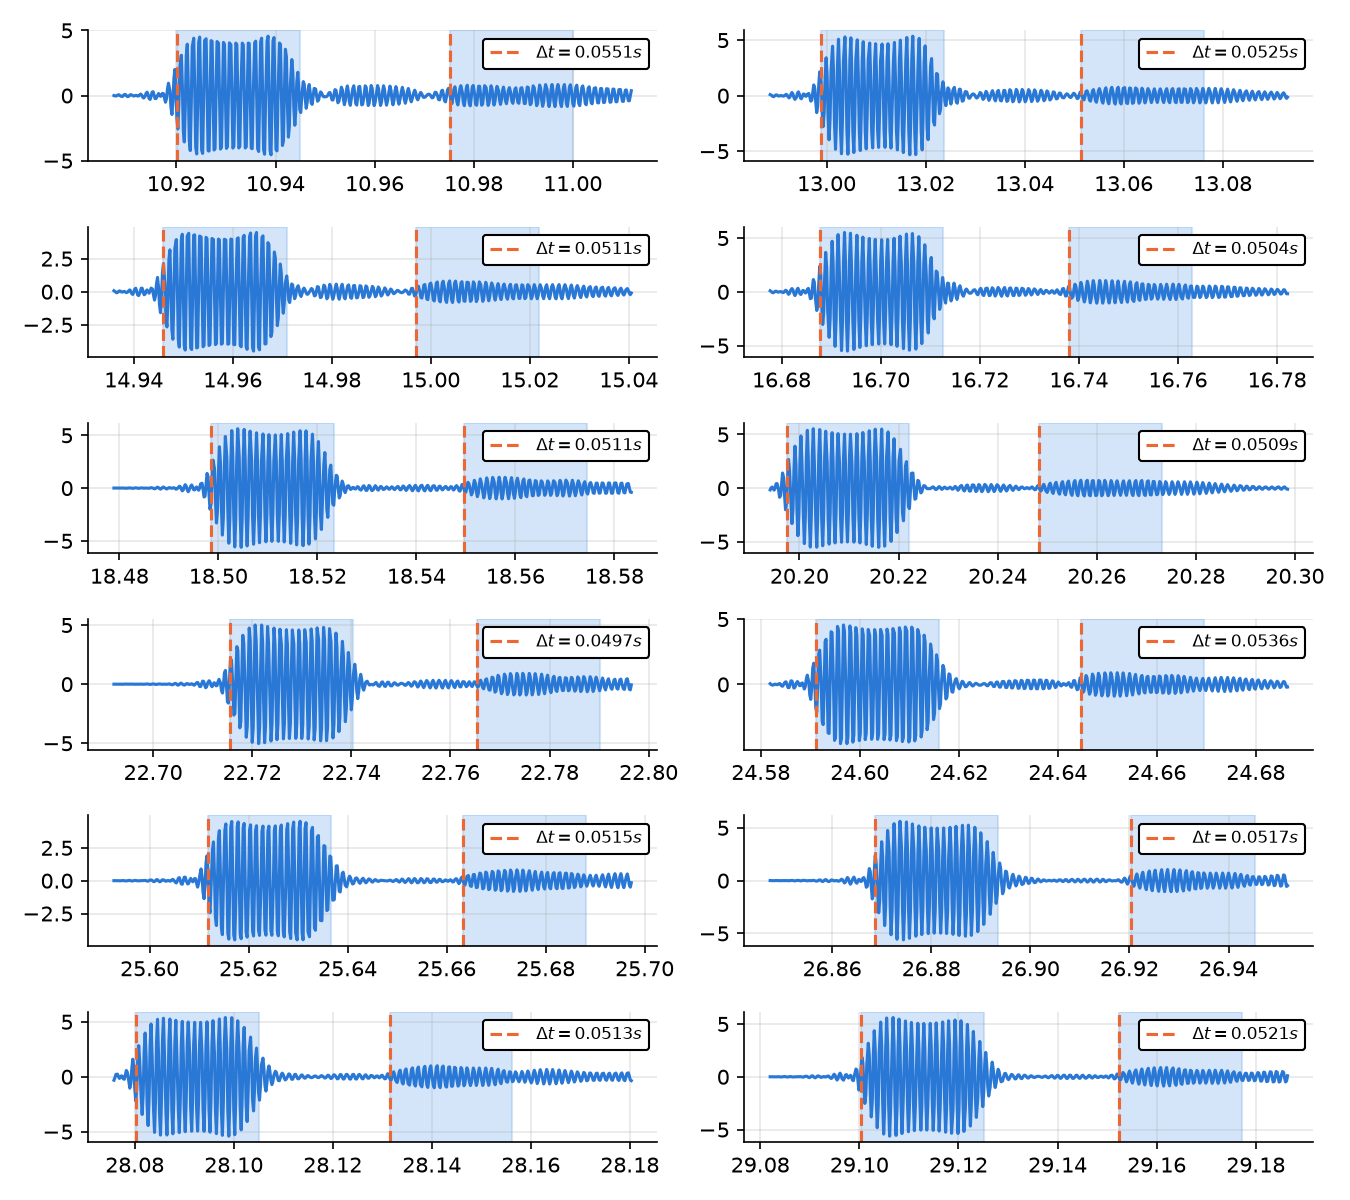

In [22]:
%matplotlib widget
from scipy.signal import butter, sosfiltfilt

peaks, _ = find_peaks(signal, prominence=2, distance=2000)

n_to_t = len(signal) / (t[-1] - t[0])
print(n_to_t)
n = lambda t: int(t * n_to_t)
cutoffs = [
    (
        max(0, int(peak - n(0.025))),
        min(len(signal), int(peak + n(0.08))),
    )
    for peak in peaks
]

# Bandpass um den Testton: fs ≈ 4797 Hz < 2 · 4000 Hz -> der 4000-Hz-Ton
# erscheint durch Aliasing bei fs - 4000 Hz ≈ 797 Hz. Alles außerhalb von
# ±100 Hz um diese Frequenz (Rauschen, 50-Hz-Brummen, ...) wird unterdrückt.
fs = n_to_t
f_alias = fs - 4000
sos = butter(4, [f_alias - 100, f_alias + 100], btype="band", fs=fs, output="sos")
signal_f = sosfiltfilt(sos, signal)  # vorwärts + rückwärts -> keine Zeitverschiebung

# print(n_to_t)
# for peak in peaks:
#     print(f"Peak: {peak}")
#     print(f"Lower bound: {int(peak - 0.2 * n_to_t)}")
#     print(f"Upper bound: {int(peak + 0.8 * n_to_t)}")

# plt.plot(t, signal, color=blau)
# plt.plot(t[peaks], signal[peaks], "x", color=orange, label="Peaks")
# plt.show()
lines = [
    (n(10.92), n(10.975)),
    (n(12.9986), n(13.0513)),
    (n(14.9458), n(14.9969)),
    (n(16.6874), n(16.738)),
    (n(18.4983), n(18.5494)),
    (n(20.1972), n(20.248)),
    (n(22.7154), n(22.765)),
    (n(24.5909), n(24.6444)),
    (n(25.6115), n(25.6631)),
    (n(26.8685), n(26.9202)),
    (n(28.08), n(28.1312)),
    (n(29.1), n(29.1522)),
]
# assert len(lines) == 24, "24 Linien für die 12 Plots pflegen"
fig, axs = plt.subplots(figsize=(9, 8), nrows=6, ncols=2, dpi=150)
for i in range(12):
    # axs[i // 4].set_xlabel("Zeit / s")
    # axs[i // 4].set_ylabel("Intensität / J")

    axs[i // 2, i % 2].plot(
        t[cutoffs[i][0] : cutoffs[i][1]],
        signal_f[cutoffs[i][0] : cutoffs[i][1]],  # gefiltert; ungefiltert: signal
        color=blau,
    )
    axs[i // 2, i % 2].axvline(
        t[lines[i][0]], color=orange, linestyle="--",    label=f"$\\Delta t = {  t[lines[i][1]] -t[lines[i][0]]:.4f} s$",

    )
    axs[i // 2, i % 2].axvline(
        t[lines[i][1]], color=orange, linestyle="--"
    )
    axs[i // 2, i % 2].axvspan(
        t[lines[i][0]], t[lines[i][0]+ n(0.025)] , color=hellblau, alpha=0.35
    )
    axs[i // 2, i % 2].axvspan(
        t[lines[i][1]], t[lines[i][1] + n(0.025)], color=hellblau, alpha=0.35
    )
    axs[i // 2, i % 2].legend(loc="upper right", fontsize=8)

# # Hover: zeigt t (und Signal) an der Mausposition, mit 4 Nachkommastellen
# hover_lines, hover_texts = {}, {}
# for ax in axs.flat:
#     ax.format_coord = lambda x, y: f"t = {x:.4f} s   Signal = {y:.3f}"
#     hover_lines[ax] = ax.axvline(np.nan, color=schwarz, lw=0.8, alpha=0.6)
#     hover_texts[ax] = ax.text(
#         0.01, 0.95, "", transform=ax.transAxes, va="top", fontsize=8,
#         bbox=dict(facecolor="white", edgecolor="none", alpha=0.8),
#     )


# def on_move(event):
#     for ax in axs.flat:
#         aktiv = event.inaxes is ax and event.xdata is not None
#         hover_lines[ax].set_visible(aktiv)
#         hover_texts[ax].set_visible(aktiv)
#         if aktiv:
#             hover_lines[ax].set_xdata([event.xdata, event.xdata])
#             hover_texts[ax].set_text(f"t = {event.xdata:.4f} s")
#     event.canvas.draw_idle()


# fig.canvas.mpl_connect("motion_notify_event", on_move)
fig.tight_layout()
plt.show()

### Erste Messreihe entfernen da Hintergrundrauschen zu groß

In [17]:
delta_t = np.array(
    [t[lines[i][1]] - t[lines[i][0]] for i in range(12) if i not in [0]]
)  # messreihe mit index 0 ignorieren
# delta_t_e = statistic(delta_t)
delta_t_e = unc.ufloat(np.mean(delta_t), 0.0006)
print(f"$\\Delta t = {delta_t_e:.uL}$")

v = 2 * d1 / delta_t_e
print(f"v={v:.uL} m/s")

$\Delta t = 0.0514 \pm 0.0006$
v=340 \pm 4 m/s


### Automatische Bestimmung von $\Delta t$
Bandpass um den Testton (durch Aliasing bei $f_s - 4000\,\text{Hz} \approx 797\,\text{Hz}$), Einhüllende über die Hilbert-Transformation, Puls- und Echo-Beginn jeweils an der steilsten Flanke der Einhüllenden.

fs = 4796.7 Hz, Testton erscheint bei 796.7 Hz
12 Pulse gefunden

 i   Δt_auto / s   Δt_hand / s
 0   0.0521        0.0551
 1   0.0519        0.0525
 2   0.0505        0.0511
 3   0.0500        0.0504
 4   0.0513        0.0511
 5   0.0505        0.0509
 6   0.0517        0.0497
 7   0.0519        0.0536
 8   0.0515        0.0515
 9   0.0513        0.0517
10   0.0515        0.0513
11   0.0517        0.0521

Δt_auto = 0.05132±0.00019 s   (Auflösung 1/fs = 0.21 ms)
v_auto  = 340.7±1.3 m/s


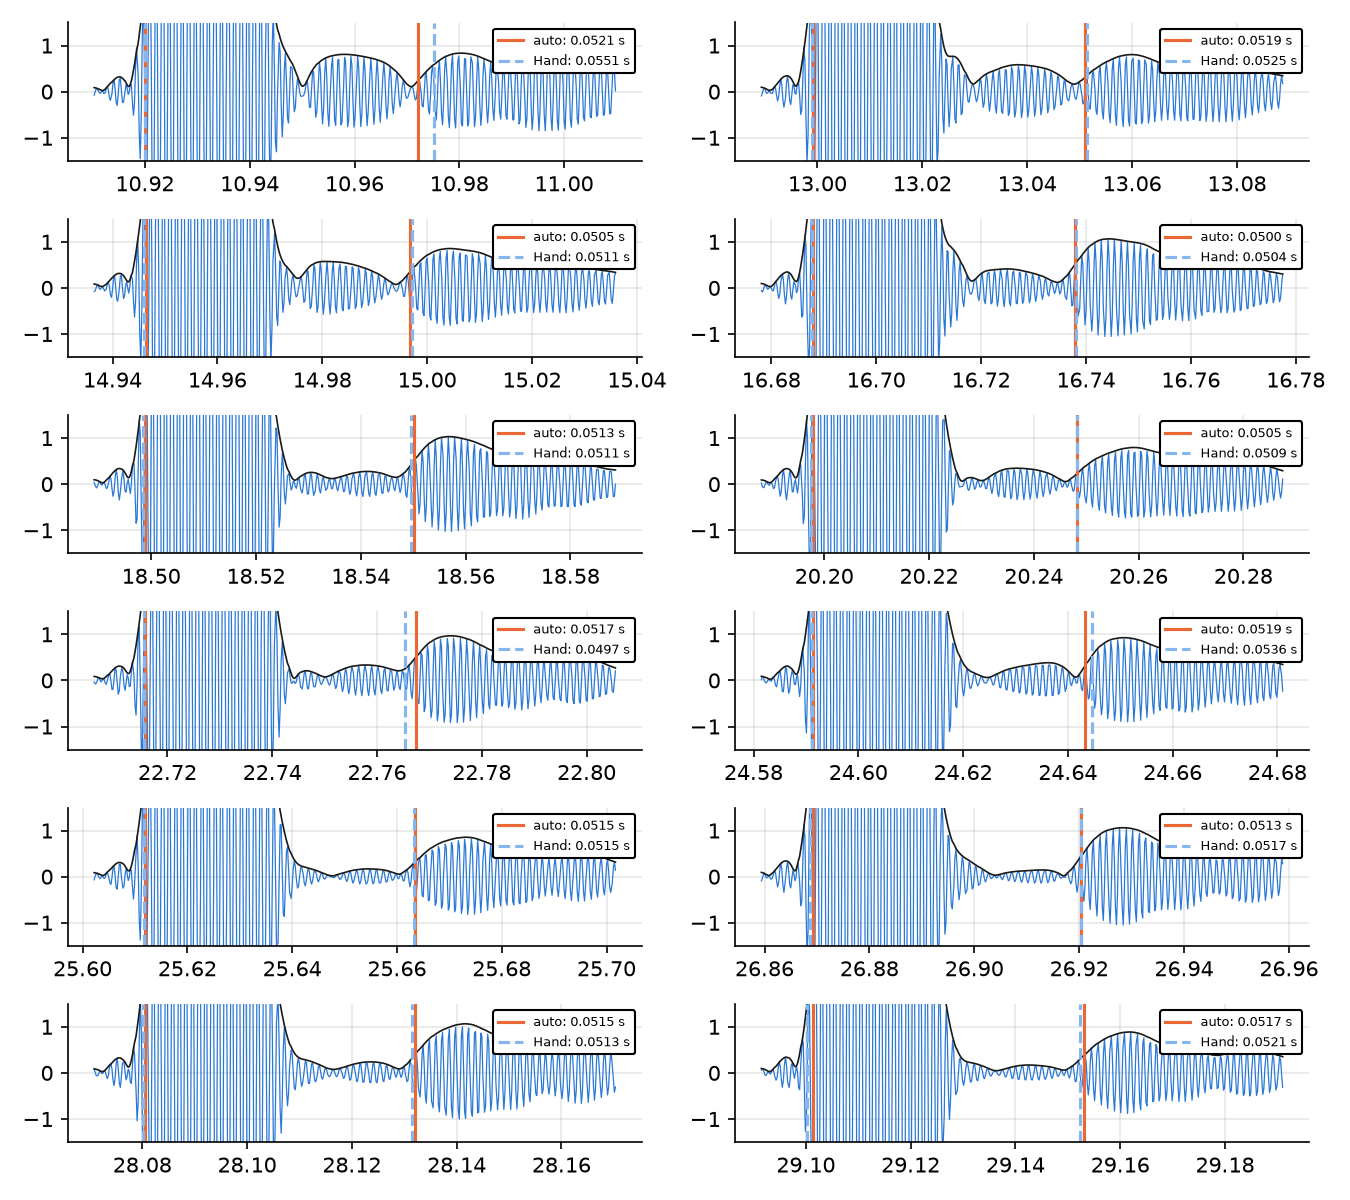

In [18]:
from scipy.signal import hilbert
from scipy.ndimage import uniform_filter1d

# --- 1. Testton isolieren: signal_f (Bandpass um 797 Hz) kommt aus Zelle 7 ----
# Einhüllende (Betrag des analytischen Signals), über 1 ms geglättet
huelle = uniform_filter1d(np.abs(hilbert(signal_f)), n(0.001))
steigung = np.gradient(huelle)

# --- 2. Puls- und Echo-Beginn = steilste Flanke der Einhüllenden ------------
pulse_peaks, _ = find_peaks(huelle, height=1, distance=n(0.4))
auto_lines = []
for pk in pulse_peaks:
    # Pulsbeginn: steilster Anstieg in den 30 ms vor dem Maximum
    i0 = pk - n(0.03) + np.argmax(steigung[pk - n(0.03) : pk])
    # Echo: Suchfenster 40–65 ms nach Pulsbeginn (erwartet ≈ 51 ms).
    # Eine frühere, schwächere Reflexion bei ≈ 30 ms liegt damit außerhalb.
    w0, w1 = i0 + n(0.04), i0 + n(0.065)
    i1 = w0 + np.argmax(steigung[w0:w1])
    auto_lines.append((i0, i1))

delta_t_auto = np.array([(i1 - i0) / fs for i0, i1 in auto_lines])
delta_t_hand = np.array([t[b] - t[a] for a, b in lines])

print(f"fs = {fs:.1f} Hz, Testton erscheint bei {f_alias:.1f} Hz")
print(f"{len(pulse_peaks)} Pulse gefunden\n")
print(" i   Δt_auto / s   Δt_hand / s")
for i, (da, dh) in enumerate(zip(delta_t_auto, delta_t_hand)):
    print(f"{i:2d}   {da:.4f}        {dh:.4f}")

# --- 3. Mittelwert und v -----------------------------------------------------
delta_t_auto_e = statistic(delta_t_auto)
v_auto = 2 * d1 / delta_t_auto_e
print(f"\nΔt_auto = {delta_t_auto_e:.uP} s   (Auflösung 1/fs = {1e3 / fs:.2f} ms)")
print(f"v_auto  = {v_auto:.uP} m/s")

# --- 4. Kontrollplot: gefiltertes Signal, Einhüllende, auto vs. Hand ---------
fig, axs = plt.subplots(figsize=(9, 8), nrows=6, ncols=2, dpi=150)
for i, ax in enumerate(axs.flat):
    i0, i1 = auto_lines[i]
    a, b = i0 - n(0.01), i0 + n(0.09)
    ax.plot(t[a:b], signal_f[a:b], color=blau, lw=0.6)
    ax.plot(t[a:b], huelle[a:b], color=schwarz, lw=0.8)
    ax.axvline(t[i0], color=orange, label=f"auto: {delta_t_auto[i]:.4f} s")
    ax.axvline(t[i1], color=orange)
    ax.axvline(
        t[lines[i][0]], color=hellblau, ls="--", label=f"Hand: {delta_t_hand[i]:.4f} s"
    )
    ax.axvline(t[lines[i][1]], color=hellblau, ls="--")
    ax.set_ylim(-1.5, 1.5)  # Echo sichtbar machen, Puls ist abgeschnitten
    ax.legend(loc="upper right", fontsize=6)
fig.tight_layout()
plt.show()

### Fourier-Koeffizient des Testtons über die Zeit (STFT)
Da $f_s \approx 4797\,\text{Hz} < 2 \cdot 4000\,\text{Hz}$, wird der 4000-Hz-Ton unterabgetastet und erscheint im Spektrum gespiegelt bei $|4000\,\text{Hz} - f_s| \approx 797\,\text{Hz}$ (Aliasing). Die gleitende Fourier-Transformation entspricht einem Bandpass mit Einhüllender und stimmt daher mit der Hilbert-Einhüllenden überein.

 i   Δt_STFT / s   Δt_Hilbert / s   Δt_Hand / s
 0   0.0511        0.0521           0.0551
 1   0.0507        0.0519           0.0525
 2   0.0502        0.0505           0.0511
 3   0.0500        0.0500           0.0504
 4   0.0505        0.0513           0.0511
 5   0.0502        0.0505           0.0509
 6   0.0505        0.0517           0.0497
 7   0.0513        0.0519           0.0536
 8   0.0505        0.0515           0.0515
 9   0.0505        0.0513           0.0517
10   0.0505        0.0515           0.0513
11   0.0502        0.0517           0.0521

Δt_STFT    = 0.05050±0.00010 s   ->  v = 346.2±0.7 m/s
Δt_Hilbert = 0.05132±0.00019 s   ->  v = 340.7±1.3 m/s


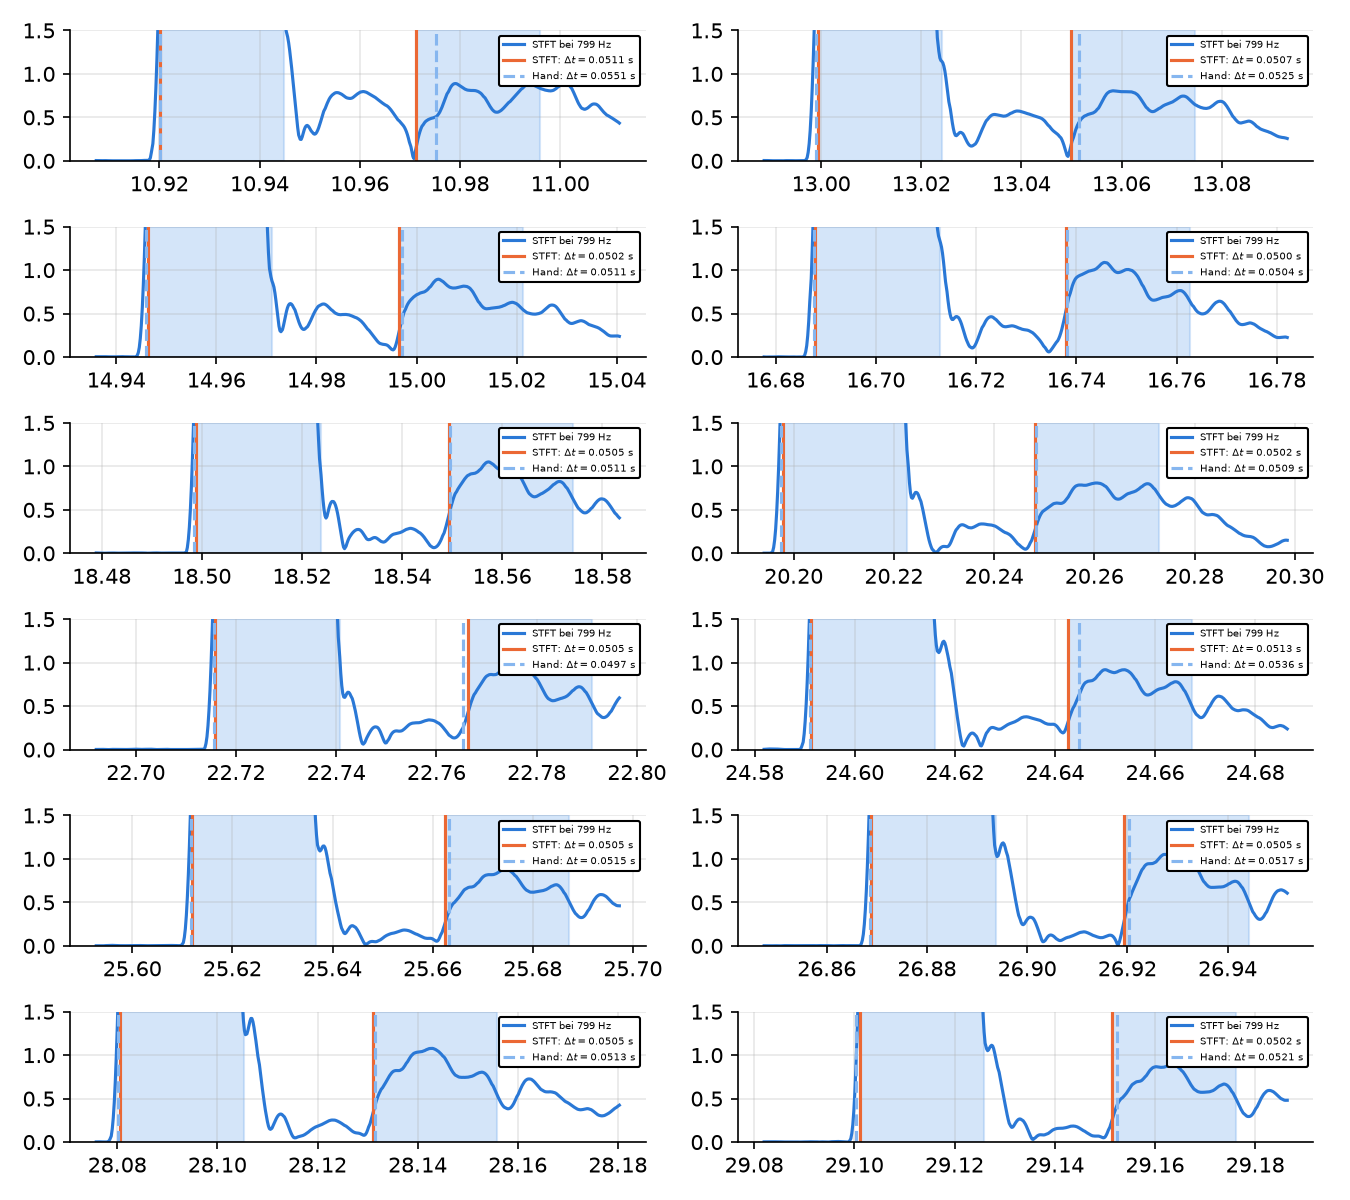

In [19]:
from scipy.signal import ShortTimeFFT
from scipy.signal.windows import hann

# Gleitende Fourier-Transformation (STFT): Hann-Fenster, Schrittweite 1 Sample
# 24 Samples ≈ 5 ms -> Frequenzauflösung fs / 24 ≈ 200 Hz,
# der 4. Koeffizient liegt dann bei ≈ 799 Hz, also genau beim (gespiegelten) Testton
N_fenster = 24
SFT = ShortTimeFFT(hann(N_fenster), hop=1, fs=fs, scale_to="magnitude")
k = np.argmin(np.abs(SFT.f - f_alias))

# Koeffizient für das ganze Signal; Fenster p ist um Sample p zentriert
X_k = SFT.stft(signal)[k]
X_k = X_k[-SFT.p_min : -SFT.p_min + len(signal)]
amp_stft = 2 * np.abs(X_k)  # ×2: einseitiges Spektrum -> Amplitude

# --- Δt aus dem Koeffizienten: steilste Flanke, wie bei der Hilbert-Methode ---
steigung_stft = np.gradient(amp_stft)
stft_peaks, _ = find_peaks(amp_stft, height=1, distance=n(0.4))
stft_lines = []
for pk in stft_peaks:
    i0 = pk - n(0.03) + np.argmax(steigung_stft[pk - n(0.03) : pk])
    w0, w1 = i0 + n(0.04), i0 + n(0.08)  # Suchfenster Echo: 40–65 ms
    i1 = w0 + np.argmax(steigung_stft[w0:w1])
    stft_lines.append((i0, i1))

delta_t_stft = np.array([(i1 - i0) / fs for i0, i1 in stft_lines])
delta_t_stft_e = statistic(delta_t_stft)
v_stft = 2 * d1 / delta_t_stft_e

print(" i   Δt_STFT / s   Δt_Hilbert / s   Δt_Hand / s")
for i, (ds, dh, dm) in enumerate(zip(delta_t_stft, delta_t_auto, delta_t_hand)):
    print(f"{i:2d}   {ds:.4f}        {dh:.4f}           {dm:.4f}")
print(f"\nΔt_STFT    = {delta_t_stft_e:.uP} s   ->  v = {v_stft:.uP} m/s")
print(f"Δt_Hilbert = {delta_t_auto_e:.uP} s   ->  v = {v_auto:.uP} m/s")

# --- Plot: STFT-Koeffizient, Linien aus STFT (orange) und von Hand (hellblau) --
fig, axs = plt.subplots(figsize=(9, 8), nrows=6, ncols=2, dpi=150)
for i, ax in enumerate(axs.flat):
    a, b = cutoffs[i]
    i0, i1 = stft_lines[i]
    ax.plot(t[a:b], amp_stft[a:b], color=blau, label=f"STFT bei {SFT.f[k]:.0f} Hz")
    ax.axvline(
        t[i0], color=orange, label=f"STFT: $\\Delta t = {delta_t_stft[i]:.4f}$ s"
    )
    ax.axvline(t[i1], color=orange)
    # Dauer des Testtons (25 ms) ab Puls- bzw. Echo-Beginn
    ax.axvspan(t[i0], t[i0 + n(0.025)], color=hellblau, alpha=0.35)
    ax.axvspan(t[i1], t[i1 + n(0.025)], color=hellblau, alpha=0.35)
    ax.axvline(
        t[lines[i][0]],
        color=hellblau,
        ls="--",
        label=f"Hand: $\\Delta t = {delta_t_hand[i]:.4f}$ s",
    )
    ax.axvline(t[lines[i][1]], color=hellblau, ls="--")
    ax.set_ylim(0, 1.5)  # Echo sichtbar machen, Puls ist abgeschnitten
    ax.legend(loc="upper right", fontsize=5)
fig.tight_layout()
fig.savefig(f"{fig_path}/stft_koeffizient.pdf")
plt.show()

Berechnetes $v_{schall} =  \frac{2 * d_1}{\Delta t}$ mit Modell aus Skript vergleichen $v_{schall}(T) = \sqrt{\frac{\gamma R T}{M}}$

T = 299.750±0.018 K   ->   v_Modell = 347.0 m/s

Methode   v / (m/s)       v - v_Modell / (m/s)   Abweichung / σ_v
STFT      346.2±0.7           -0.8                 -1.1


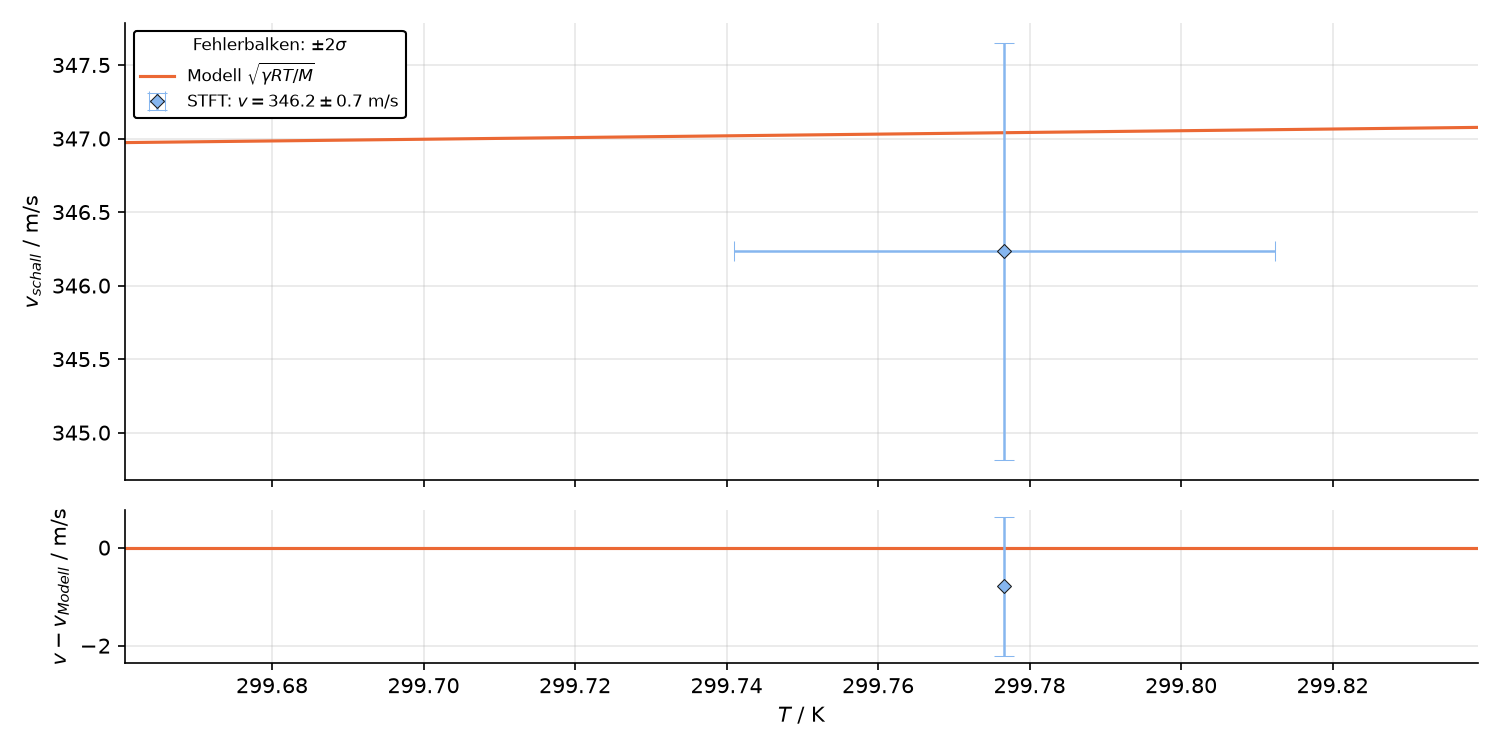

In [20]:
# Kelvin = lambda T: T + 273.15  # Umrechnung in Kelvin

model = lambda T: np.sqrt(1.4 * 8.3143 * T / 0.028973)
model_T = np.linspace(T.n - 5 * T.s, T.n + 5 * T.s, 1000)

n_sigma = 2  # Anzahl der Standardabweichungen für Fehlerbalken

# Alle Messwerte liegen bei derselben Temperatur; für die Lesbarkeit werden sie
# horizontal leicht gegeneinander versetzt (dx, nur Darstellung).
messungen = [
    # (Name,     v,      Farbe,    Marker, dx)
    # ("Hand", v, blau, "o", -1.5 * T.s),
    # ("Hilbert", v_auto, schwarz, "s", 0.0),
    ("STFT", v_stft, hellblau, "D", +1.5 * T.s),
]

print(f"T = {T:.uP} K   ->   v_Modell = {model(T.n):.1f} m/s\n")
print("Methode   v / (m/s)       v - v_Modell / (m/s)   Abweichung / σ_v")
for name, vi, *_ in messungen:
    res = vi.n - model(T.n)
    print(f"{name:8s}  {f'{vi:.uP}':14s}  {res:+8.1f}               {res / vi.s:+6.1f}")

fig, axs = plt.subplots(
    figsize=(10, 5), dpi=150, nrows=2, ncols=1, sharex=True, height_ratios=[3, 1]
)

axs[0].plot(
    model_T, model(model_T), color=orange, label="Modell $\\sqrt{\\gamma R T / M}$"
)
axs[1].axhline(0, color=orange)

for name, vi, farbe, marker, dx in messungen:
    stil = dict(
        fmt=marker,
        capsize=5,
        color=farbe,
        ecolor=farbe,
        elinewidth=1.2,
        markeredgecolor=schwarz,
        markeredgewidth=0.5,
        markersize=5,
    )
    axs[0].errorbar(
        x=T.n + dx,
        y=vi.n,
        xerr=n_sigma * T.s,
        yerr=n_sigma * vi.s,
        label=f"{name}: $v = {vi:.1uL}$ m/s",
        **stil,
    )
    # Residuum in m/s, Fehlerbalken ± n_sigma · σ_v
    axs[1].errorbar(x=T.n + dx, y=vi.n - model(T.n), yerr=n_sigma * vi.s, **stil)

axs[0].set_ylabel("$v_{schall}$ / m/s")
axs[0].legend(
    loc="upper left",
    fontsize=8,
    title=f"Fehlerbalken: $\\pm {n_sigma}\\sigma$",
    title_fontsize=8,
)
axs[1].set_xlim(model_T[0], model_T[-1])
axs[1].set_ylabel("$v - v_{Modell}$ / m/s")
axs[1].set_xlabel("$T$ / K")
fig.tight_layout()
fig.savefig(f"{fig_path}/v_modellvergleich.pdf")
plt.show()